In [14]:
import gc
import io
import json
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageFilter
from IPython.display import display
from tqdm.auto import tqdm
from google.colab import files

Загрузите несколько изображений (JPG/PNG/WEBP), выбрав их одновременно:


Saving car.webp to car (1).webp
Saving image.jpg to image (1).jpg
Saving madk1d.jpg to madk1d (1).jpg
01_image: car (1).webp, HR: (256, 256)


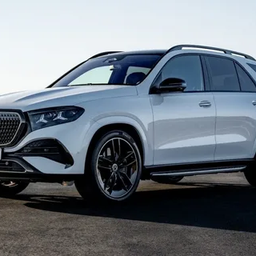

02_image: image (1).jpg, HR: (256, 256)


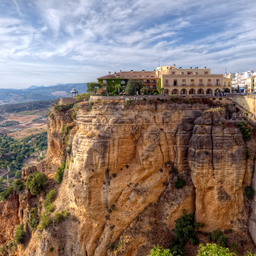

03_image: madk1d (1).jpg, HR: (256, 256)


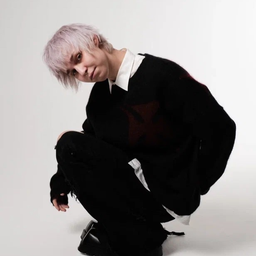

773

In [15]:
HR_SIZE = 256
STEPS = 50
GUIDANCE = 2.0
NOISE_LEVEL = 5
STRENGTH = 0.40
BLEND_ALPHA = 0.85
SEED = 42
PROMPT = "photograph, faithful structure, natural textures"
NEGATIVE_PROMPT = "distorted geometry, painting, artificial textures, oversaturation, artifacts"

if not torch.cuda.is_available():
    raise RuntimeError("Необходим GPU")
DEVICE = "cuda"
np.random.seed(SEED)
torch.manual_seed(SEED)

RESULTS = Path("/content/CV3_results")
if RESULTS.exists():
    shutil.rmtree(RESULTS)
for folder in ("input", "degraded", "masks", "outputs", "comparisons", "plots"):
    (RESULTS / folder).mkdir(parents=True, exist_ok=True)

print("Загрузите несколько изображений (JPG/PNG/WEBP), выбрав их одновременно:")
uploaded = files.upload()
if not uploaded:
    raise ValueError("Загрузите хотя бы одно изображение")
images = {}
source_files = {}
for index, (filename, image_bytes) in enumerate(uploaded.items(), start=1):
    image_id = f"{index:02d}_image"
    with Image.open(io.BytesIO(image_bytes)) as original:
        img = original.convert("RGB")
        side = min(img.size)
        x, y = (img.width - side) // 2, (img.height - side) // 2
        hr = img.crop((x, y, x + side, y + side)).resize(
            (HR_SIZE, HR_SIZE), Image.Resampling.LANCZOS
        )
    images[image_id] = hr
    source_files[image_id] = filename
    hr.save(RESULTS / "input" / f"{image_id}_HR.png")
    print(f"{image_id}: {filename}, HR: {hr.size}")
    display(hr)
if len(images) < 2:
    print("Для выполнения задания рекомендуется загрузить несколько изображений.")
(RESULTS / "config.json").write_text(json.dumps({
    "source_files": source_files, "image_count": len(images), "hr_size": HR_SIZE, "scale": 4,
    "steps": STEPS, "guidance": GUIDANCE, "noise_level": NOISE_LEVEL,
    "strength": STRENGTH, "blend_alpha": BLEND_ALPHA, "scheduler": "DDIMScheduler",
    "seed": SEED, "prompt": PROMPT, "negative_prompt": NEGATIVE_PROMPT,
    "model": "stabilityai/stable-diffusion-x4-upscaler",
    "degradations": ["bicubic_x4", "unknown_x4", "realesrgan_like_x4"],
    "masks": ["zeros", "ones", "center"],
    "mask_value_1": "allow diffusion restoration",
    "mask_value_0": "keep bicubic baseline"
}, ensure_ascii=False, indent=2), encoding="utf-8")

## Деградации

/tmp/ipykernel_689/512676405.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(arr, "RGB")


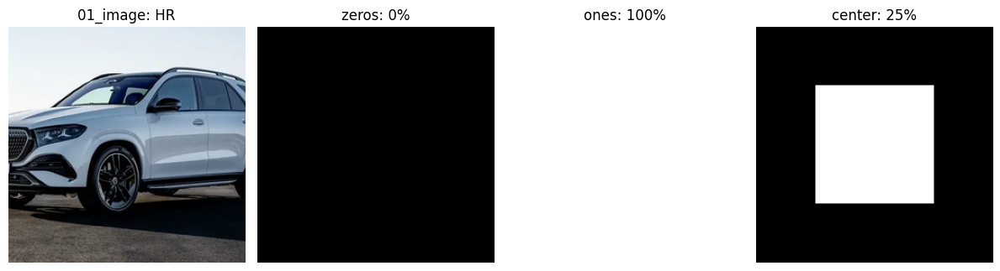

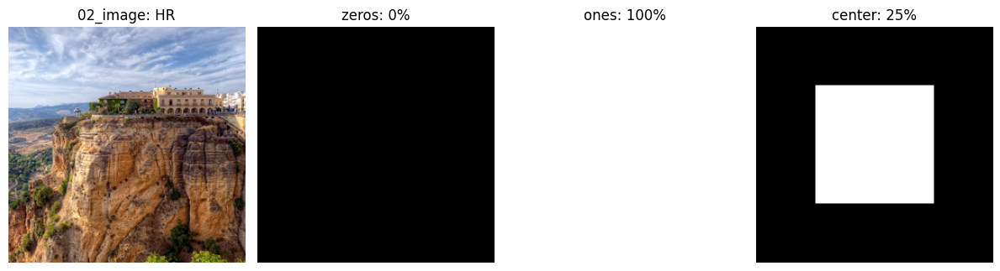

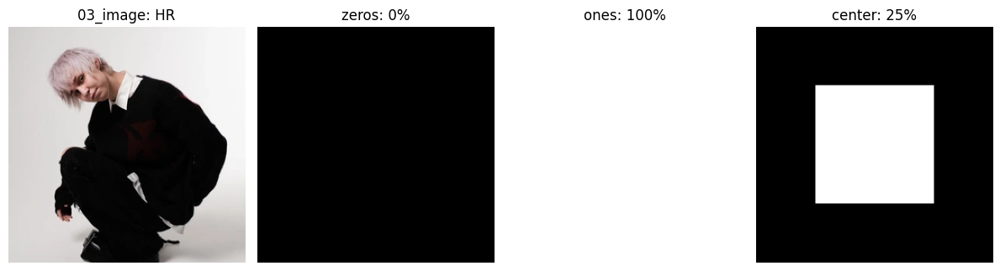

In [16]:
LQ_SIZE = HR_SIZE // 4
DEGRADATIONS = ("bicubic_x4", "unknown_x4", "realesrgan_like_x4")
MASKS = ("zeros", "ones", "center")


def jpeg(image, quality):
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=quality)
    buffer.seek(0)
    return Image.open(buffer).convert("RGB")


def add_noise(image, rng, sigma):
    arr = np.asarray(image, dtype=np.float32)
    arr = np.clip(arr + rng.normal(0, sigma, arr.shape), 0, 255).astype(np.uint8)
    return Image.fromarray(arr, "RGB")


def create_degradations(image):
    rng = np.random.default_rng(SEED)
    bicubic = image.resize((LQ_SIZE, LQ_SIZE), Image.Resampling.BICUBIC)
    blurred = image.filter(ImageFilter.GaussianBlur(1.6))
    unknown = jpeg(add_noise(blurred.resize((LQ_SIZE, LQ_SIZE), Image.Resampling.BICUBIC), rng, 10), 50)
    complex_ = image.filter(ImageFilter.GaussianBlur(1.0))
    complex_ = complex_.resize((LQ_SIZE * 2, LQ_SIZE * 2), Image.Resampling.BICUBIC)
    complex_ = jpeg(complex_, 60).resize((LQ_SIZE, LQ_SIZE), Image.Resampling.BILINEAR)
    complex_ = jpeg(add_noise(complex_, rng, 6), 55)
    return {
        "bicubic_x4": bicubic,
        "unknown_x4": unknown,
        "realesrgan_like_x4": complex_,
    }


def create_masks():
    zeros = np.zeros((LQ_SIZE, LQ_SIZE), dtype=np.uint8)
    center = zeros.copy()
    q = LQ_SIZE // 4
    center[q:3*q, q:3*q] = 1
    ones = np.ones((LQ_SIZE, LQ_SIZE), dtype=np.uint8)
    return {"zeros": zeros, "ones": ones, "center": center}


def mask_at_hr(mask):
    return np.asarray(Image.fromarray(mask * 255).resize((HR_SIZE, HR_SIZE), Image.Resampling.NEAREST)) > 0


masks = create_masks()
assert tuple(masks) == MASKS
for name, mask in masks.items():
    Image.fromarray(mask * 255).save(RESULTS / "masks" / f"{name}_lq.png")
    Image.fromarray((mask_at_hr(mask) * 255).astype(np.uint8)).save(
        RESULTS / "masks" / f"{name}.png")

degraded_images = {}
for image_id, hr in images.items():
    lq_images = create_degradations(hr)
    degraded_images[image_id] = lq_images
    assert tuple(lq_images) == DEGRADATIONS
    for name, lq in lq_images.items():
        lq.save(RESULTS / "degraded" / f"{image_id}_{name}_lq.png")
        lq.resize(hr.size, Image.Resampling.BICUBIC).save(
            RESULTS / "degraded" / f"{image_id}_{name}_bicubic_HR.png")
    fig, axes = plt.subplots(1, 4, figsize=(12, 3.3))
    axes[0].imshow(hr)
    axes[0].set_title(f"{image_id}: HR")
    for ax, (name, mask) in zip(axes[1:], masks.items()):
        ax.imshow(mask_at_hr(mask), cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"{name}: {mask.mean():.0%}")
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)

## Диффузиозная модель

In [17]:
from diffusers import StableDiffusionUpscalePipeline, DDIMScheduler
import torch.nn.functional as F

pipe = StableDiffusionUpscalePipeline.from_pretrained(
    "stabilityai/stable-diffusion-x4-upscaler",
    torch_dtype=torch.float16
).to(DEVICE)
pipe.scheduler = DDIMScheduler.from_config(pipe.scheduler.config)
pipe.vae.to(dtype=torch.float32)
pipe.enable_attention_slicing()
print("Загружена Stable Diffusion ×4, GPU:", torch.cuda.get_device_name(0))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

There are modules in AutoencoderKL that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Загружена Stable Diffusion ×4, GPU: Tesla T4


In [18]:
@torch.inference_mode()
def masked_super_resolution(lq: Image.Image, mask: np.ndarray, seed: int) -> Image.Image:
    assert mask.shape == (lq.height, lq.width) and np.isin(mask, [0, 1]).all()
    baseline = lq.resize((HR_SIZE, HR_SIZE), Image.Resampling.BICUBIC)
    if mask.max() == 0:
        return baseline.copy()

    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    dtype = next(pipe.unet.parameters()).dtype
    use_cfg = GUIDANCE > 1
    pos, neg = pipe.encode_prompt(PROMPT, DEVICE, 1, use_cfg, NEGATIVE_PROMPT)
    prompts = torch.cat([neg, pos]) if use_cfg else pos

    condition = pipe.image_processor.preprocess(lq).to(device=DEVICE, dtype=dtype)
    level = torch.tensor([NOISE_LEVEL], device=DEVICE, dtype=torch.long)
    noise = torch.randn(condition.shape, device=DEVICE, dtype=dtype, generator=generator)
    noisy_condition = pipe.low_res_scheduler.add_noise(condition, noise, level)
    repeats = 2 if use_cfg else 1
    noisy_condition = noisy_condition.repeat(repeats, 1, 1, 1)
    class_labels = level.repeat(repeats)

    baseline_tensor = pipe.image_processor.preprocess(baseline).to(device=DEVICE, dtype=pipe.vae.dtype)
    known = pipe.vae.encode(baseline_tensor).latent_dist.mode() * pipe.vae.config.scaling_factor
    known = known.to(dtype=dtype)

    if known.shape[-2:] != condition.shape[-2:]:
        raise ValueError(f"VAE latent shape {known.shape[-2:]} != LQ {condition.shape[-2:]}")
    mask_latent = torch.as_tensor(mask[None, None].copy(), device=DEVICE, dtype=dtype)
    fixed_noise = torch.randn(known.shape, device=DEVICE, dtype=dtype, generator=generator)

    pipe.scheduler.set_timesteps(STEPS, device=DEVICE)
    init_steps = max(1, min(int(STEPS * STRENGTH), STEPS))
    timesteps = pipe.scheduler.timesteps[STEPS - init_steps:]
    latents = pipe.scheduler.add_noise(known, fixed_noise, timesteps[:1])
    step_kwargs = pipe.prepare_extra_step_kwargs(generator, eta=0.0)
    for i, t in enumerate(timesteps):
        model_in = torch.cat([latents] * repeats) if use_cfg else latents
        model_in = pipe.scheduler.scale_model_input(model_in, t)
        model_in = torch.cat([model_in, noisy_condition], dim=1)
        noise_pred = pipe.unet(model_in, t, encoder_hidden_states=prompts,
                               class_labels=class_labels, return_dict=False)[0]
        if use_cfg:
            uncond, text = noise_pred.chunk(2)
            noise_pred = uncond + GUIDANCE * (text - uncond)
        latents = pipe.scheduler.step(noise_pred, t, latents, **step_kwargs, return_dict=False)[0]
        if i + 1 < len(timesteps):
            known_step = pipe.scheduler.add_noise(known, fixed_noise, timesteps[i+1:i+2])
        else:
            known_step = known
        latents = mask_latent * latents + (1 - mask_latent) * known_step

    decoded = pipe.vae.decode(latents.to(pipe.vae.dtype) / pipe.vae.config.scaling_factor,
                              return_dict=False)[0]
    if not torch.isfinite(decoded).all():
        raise RuntimeError("VAE returned NaN or Inf")
    generated = pipe.image_processor.postprocess(decoded.float(), output_type="pil")[0].convert("RGB")
    if generated.size != baseline.size:
        generated = generated.resize(baseline.size, Image.Resampling.BICUBIC)
    mask_hr = mask_at_hr(mask)
    base_arr = np.asarray(baseline, dtype=np.float32)
    gen_arr = np.asarray(generated, dtype=np.float32)
    if not np.isfinite(gen_arr).all():
        raise RuntimeError("Non-finite generated image")
    blended = np.rint(np.clip(base_arr + BLEND_ALPHA * (gen_arr - base_arr), 0, 255)).astype(np.uint8)
    out = np.where(mask_hr[..., None], blended, np.asarray(baseline))
    return Image.fromarray(out)

## Эксперименты

In [19]:
for image_id, hr in tqdm(images.items(), desc="Изображения"):
    lq_images = degraded_images[image_id]
    for i, (degradation, lq) in enumerate(tqdm(lq_images.items(), desc="Обработка деградаций")):
        baseline = np.asarray(lq.resize(hr.size, Image.Resampling.BICUBIC))
        for mask_name, mask in tqdm(masks.items(), desc=degradation, leave=False):
            target = RESULTS / "outputs" / f"{image_id}_{degradation}_{mask_name}.png"
            result = masked_super_resolution(lq, mask, seed=SEED + i)
            result_arr = np.asarray(result)
            roi = mask_at_hr(mask)
            assert np.array_equal(result_arr[~roi], baseline[~roi]), (
                "Пиксели вне маски были изменены", degradation, mask_name
            )
            result.save(target)
            if roi.any() and (np.all(result_arr[roi] == 0)):
                print("ПРЕДУПРЕЖДЕНИЕ: модель вернула полностью чёрную область:", target.name)
            print("Сохранено:", target.name)
        torch.cuda.empty_cache()

print(f"Сохранено {len(images) * len(DEGRADATIONS) * len(MASKS)} PNG:", RESULTS / "outputs")

Изображения:   0%|          | 0/3 [00:00<?, ?it/s]

Обработка деградаций:   0%|          | 0/3 [00:00<?, ?it/s]

bicubic_x4:   0%|          | 0/3 [00:00<?, ?it/s]

Сохранено: 01_image_bicubic_x4_zeros.png
Сохранено: 01_image_bicubic_x4_ones.png
Сохранено: 01_image_bicubic_x4_center.png


unknown_x4:   0%|          | 0/3 [00:00<?, ?it/s]

Сохранено: 01_image_unknown_x4_zeros.png
Сохранено: 01_image_unknown_x4_ones.png
Сохранено: 01_image_unknown_x4_center.png


... (12 outputs left out)

unknown_x4:   0%|          | 0/3 [00:00<?, ?it/s]

Сохранено: 03_image_unknown_x4_zeros.png
Сохранено: 03_image_unknown_x4_ones.png
Сохранено: 03_image_unknown_x4_center.png


realesrgan_like_x4:   0%|          | 0/3 [00:00<?, ?it/s]

Сохранено: 03_image_realesrgan_like_x4_zeros.png
Сохранено: 03_image_realesrgan_like_x4_ones.png
Сохранено: 03_image_realesrgan_like_x4_center.png
Сохранено 27 PNG: /content/CV3_results/outputs


In [8]:
!pip install pyiqa

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.4 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 117.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 72.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.8/5.8 MB 170.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 164.7 MB/s  0:00:00
  Created wheel for openai-clip: filename=openai_clip-1.0.1-py3-none-any.whl size=1368629 sha256=50f2891ca1be0cfc8f520cb787624e8c5ccc6bf41dc1b26b597cdff57f1307aa
  Stored in directory: /root/.cache/pip/wheels/bd/9c/b7/616dc2b70d8ad5a27f22c92eaa29146ee51748b5f0843a430b
Successfully built openai-clip
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16/16 [pyiqa]


## 5. Masked-метрики

In [20]:
import pyiqa

del pipe
gc.collect()
torch.cuda.empty_cache()

lpips_full = pyiqa.create_metric("lpips", device=DEVICE)
lpips_spatial = pyiqa.create_metric("lpips", spatial=True, device=DEVICE)
clipiqa = pyiqa.create_metric("clipiqa", device=DEVICE)


def to_tensor(image):
    arr = np.asarray(image.convert("RGB"), dtype=np.float32).copy() / 255.0
    return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0).to(DEVICE)


def region_psnr(pred, ref, region=None):
    pred = np.asarray(pred, dtype=np.float64)
    ref = np.asarray(ref, dtype=np.float64)
    assert pred.shape == ref.shape and pred.ndim == 3 and pred.shape[2] == 3
    if region is not None:
        assert region.shape == pred.shape[:2] and region.dtype == bool
        if not region.any():
            return float("nan")
        diff = pred[region] - ref[region]
    else:
        diff = pred - ref
    mse = np.mean(diff ** 2)
    return float("inf") if mse == 0 else float(10 * np.log10((255.0 ** 2) / mse))


def masked_lpips(spatial_map, region):
    assert spatial_map.ndim == 4 and spatial_map.shape[0:2] == (1, 1)
    assert tuple(spatial_map.shape[2:]) == region.shape
    if not region.any():
        return float("nan")
    values = spatial_map[0, 0]
    region_tensor = torch.as_tensor(region.copy(), dtype=torch.bool, device=values.device)
    return float(values[region_tensor].mean().item())


rows = []
with torch.inference_mode():
    for image_id, hr in tqdm(images.items(), desc="Метрики по изображениям"):
        lq_images = degraded_images[image_id]
        hr_arr = np.asarray(hr)
        hr_t = to_tensor(hr)
        for degradation, lq in tqdm(lq_images.items(), desc="Расчёт метрик"):
            base_img = lq.resize(hr.size, Image.Resampling.BICUBIC)
            base_arr = np.asarray(base_img)
            base_t = to_tensor(base_img)
            base_lpips_map = lpips_spatial(base_t, hr_t)
            base_full_psnr = region_psnr(base_arr, hr_arr)
            base_full_lpips = float(lpips_full(base_t, hr_t).item())
            base_clip = float(clipiqa(base_t).item())
            for mask_name, mask in masks.items():
                pred_img = Image.open(RESULTS / "outputs" / f"{image_id}_{degradation}_{mask_name}.png").convert("RGB")
                pred_arr = np.asarray(pred_img)
                pred_t = to_tensor(pred_img)
                roi = mask_at_hr(mask)
                outside = ~roi
                base_p = region_psnr(base_arr, hr_arr, roi)
                pred_p = region_psnr(pred_arr, hr_arr, roi)
                base_lp = masked_lpips(base_lpips_map, roi)
                pred_lp = masked_lpips(lpips_spatial(pred_t, hr_t), roi)
                outside_mae = (float(np.abs(pred_arr[outside].astype(float) - base_arr[outside].astype(float)).mean())
                               if outside.any() else float("nan"))
                pred_clip = float(clipiqa(pred_t).item())
                rows.append({
                    "image_id": image_id,
                    "source_file": source_files[image_id],
                    "degradation": degradation,
                    "mask": mask_name,
                    "mask_fraction": round(float(roi.mean()), 4),
                    "PSNR_full_baseline": base_full_psnr,
                    "PSNR_full_result": region_psnr(pred_arr, hr_arr),
                    "PSNR_masked_baseline": base_p,
                    "PSNR_masked_result": pred_p,
                    "delta_PSNR_masked_dB": pred_p - base_p if roi.any() else float("nan"),
                    "PSNR_unmasked_result": region_psnr(pred_arr, hr_arr, outside),
                    "LPIPS_full_baseline": base_full_lpips,
                    "LPIPS_full_result": float(lpips_full(pred_t, hr_t).item()),
                    "LPIPS_masked_baseline": base_lp,
                    "LPIPS_masked_result": pred_lp,
                    "delta_LPIPS_masked": base_lp - pred_lp if roi.any() else float("nan"),
                    "CLIP_IQA_full_baseline": base_clip,
                    "CLIP_IQA_full_result": pred_clip,
                    "delta_CLIP_IQA_full": pred_clip - base_clip,
                    "MAE_outside_vs_bicubic": outside_mae,
                })
                del pred_t

metrics = pd.DataFrame(rows)
metrics.to_csv(RESULTS / "metrics.csv", index=False, na_rep="NaN", float_format="%.8f")
display(metrics.round(4))
print("ΔPSNR_masked > 0 и ΔLPIPS_masked > 0 означают улучшение внутри маски.")
print("PSNR/LPIPS masked для zeros = NaN; PSNR unmasked для ones = NaN.")
print("Вне маски изображение должно совпадать с bicubic (MAE=0, кроме ones → NaN).")

Loading pretrained model LPIPS from /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth
Loading pretrained model LPIPS from /root/.cache/torch/hub/pyiqa/LPIPS_v0.1_alex-df73285e.pth


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Метрики по изображениям:   0%|          | 0/3 [00:00<?, ?it/s]

Расчёт метрик:   0%|          | 0/3 [00:00<?, ?it/s]

Расчёт метрик:   0%|          | 0/3 [00:00<?, ?it/s]

Расчёт метрик:   0%|          | 0/3 [00:00<?, ?it/s]

,image_id,source_file,degradation,mask,mask_fraction,PSNR_full_baseline,PSNR_full_result,PSNR_masked_baseline,PSNR_masked_result,delta_PSNR_masked_dB,PSNR_unmasked_result,LPIPS_full_baseline,LPIPS_full_result,LPIPS_masked_baseline,LPIPS_masked_result,delta_LPIPS_masked,CLIP_IQA_full_baseline,CLIP_IQA_full_result,delta_CLIP_IQA_full,MAE_outside_vs_bicubic
0,01_image,car (1).webp,bicubic_x4,zeros,0.00,23.2253,23.2253,NaN,NaN,NaN,23.2253,0.4629,0.4629,NaN,NaN,NaN,0.5104,0.5104,0.0000,0.0
1,01_image,car (1).webp,bicubic_x4,ones,1.00,23.2253,23.1760,23.2253,23.1760,-0.0493,NaN,0.4629,0.4279,0.4629,0.4279,0.0350,0.5104,0.2856,-0.2248,NaN
2,01_image,car (1).webp,bicubic_x4,center,0.25,23.2253,23.2258,21.3957,21.3970,0.0013,24.0589,0.4629,0.4483,0.4913,0.4465,0.0449,0.5104,0.4375,-0.0729,0.0
3,01_image,car (1).webp,unknown_x4,zeros,0.00,21.4096,21.4096,NaN,NaN,NaN,21.4096,0.6797,0.6797,NaN,NaN,NaN,0.2719,0.2719,0.0000,0.0
4,01_image,car (1).webp,unknown_x4,ones,1.00,21.4096,21.3965,21.4096,21.3965,-0.0131,NaN,0.6797,0.6439,0.6797,0.6440,0.0357,0.2719,0.0996,-0.1722,NaN
5,01_image,car (1).webp,unknown_x4,center,0.25,21.4096,21.4086,19.4953,19.4927,-0.0026,22.2961,0.6797,0.6729,0.7220,0.7124,0.0096,0.2719,0.2048,-0.0670,0.0
6,01_image,car (1).webp,realesrgan_like_x4,zeros,0.00,21.4829,21.4829,NaN,NaN,NaN,21.4829,0.6505,0.6505,NaN,NaN,NaN,0.2551,0.2551,0.0000,0.0
7,01_image,car (1).webp,realesrgan_like_x4,ones,1.00,21.4829,21.4447,21.4829,21.4447,-0.0382,NaN,0.6505,0.6290,0.6505,0.6290,0.0215,0.2551,0.1064,-0.1487,NaN
8,01_image,car (1).webp,realesrgan_like_x4,center,0.25,21.4829,21.4715,19.5160,19.4870,-0.0290,22.4032,0.6505,0.6475,0.7149,0.7098,0.0051,0.2551,0.1862,-0.0689,0.0
9,02_image,image (1).jpg,bicubic_x4,zeros,0.00,23.9967,23.9967,NaN,NaN,NaN,23.9967,0.5277,0.5277,NaN,NaN,NaN,0.5658,0.5658,0.0000,0.0


ΔPSNR_masked > 0 и ΔLPIPS_masked > 0 означают улучшение внутри маски.
PSNR/LPIPS masked для zeros = NaN; PSNR unmasked для ones = NaN.
Вне маски изображение должно совпадать с bicubic (MAE=0, кроме ones → NaN).


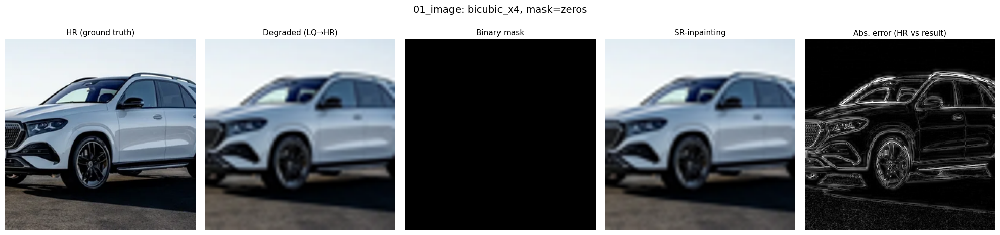

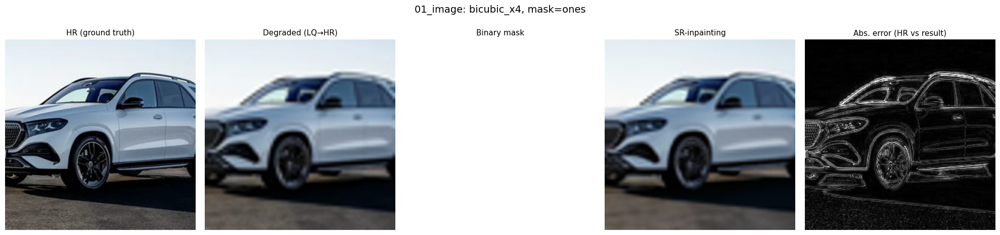

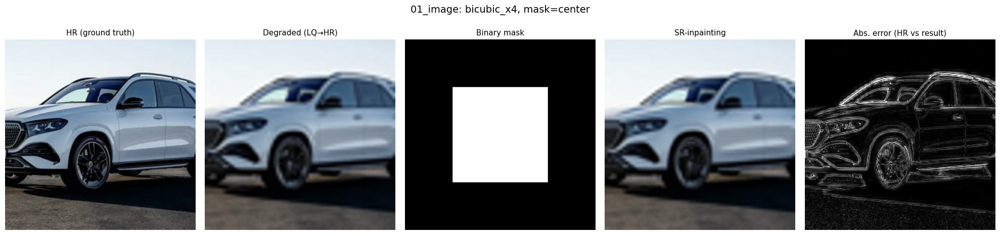

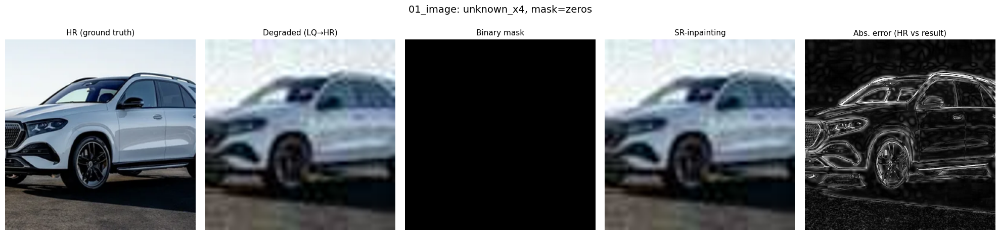

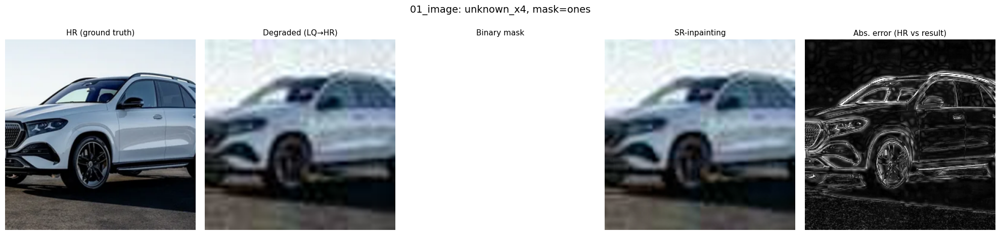

...

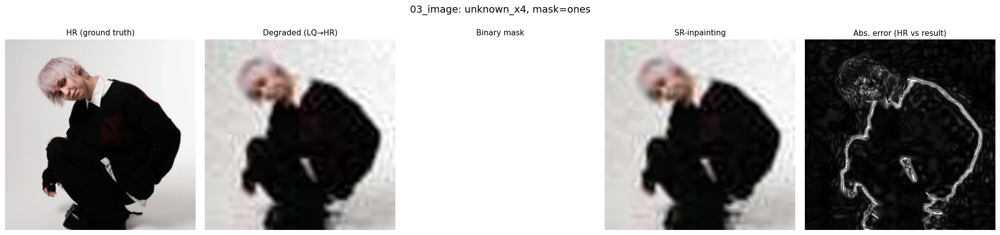

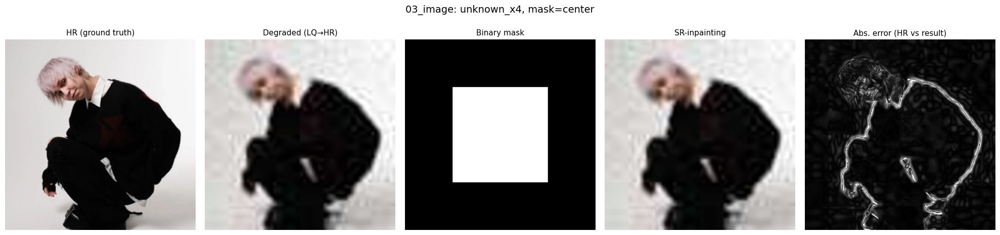

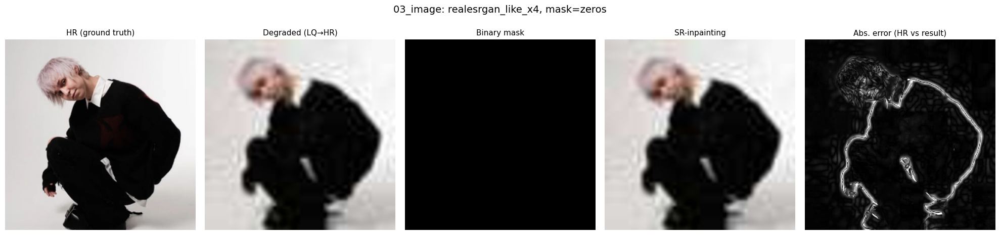

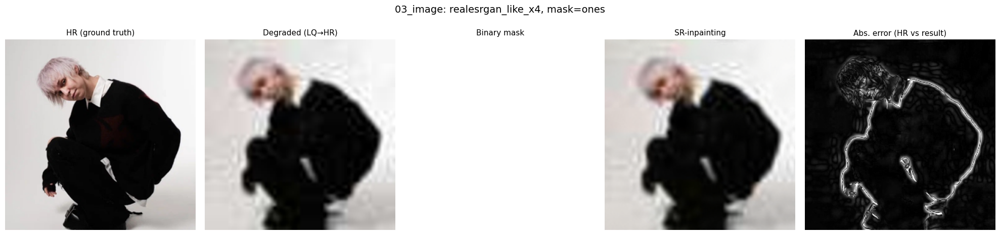

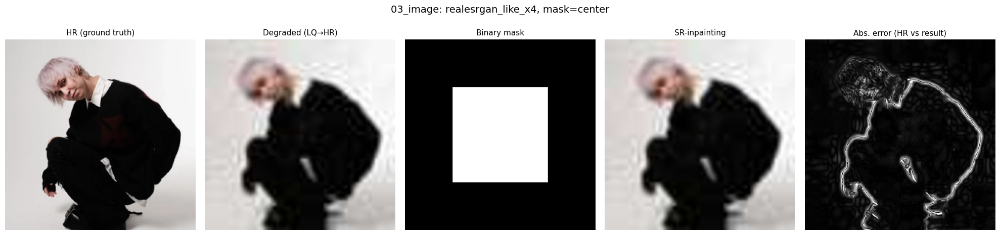

In [21]:
for image_id, hr in images.items():
    lq_images = degraded_images[image_id]

    for degradation, lq in lq_images.items():
        base = lq.resize(hr.size, Image.Resampling.BICUBIC)

        for mask_name, mask in masks.items():

            filename = f"{image_id}_{degradation}_{mask_name}.png"
            result_path = RESULTS / "outputs" / filename

            with Image.open(result_path) as f:
                sr = f.convert("RGB")

            error = np.abs(
                np.asarray(hr, dtype=np.float32) -
                np.asarray(sr, dtype=np.float32)
            ).mean(axis=2)

            fig, axes = plt.subplots(1, 5, figsize=(20, 4.7))

            panels = (hr, base, mask_at_hr(mask), sr, error)

            titles = (
                "HR (ground truth)",
                "Degraded (LQ→HR)",
                "Binary mask",
                "SR-inpainting",
                "Abs. error (HR vs result)"
            )

            for k, (ax, item, title) in enumerate(
                zip(axes, panels, titles)
            ):
                if k == 2:
                    ax.imshow(item, cmap="gray", vmin=0, vmax=1)
                elif k == 4:
                    ax.imshow(item, cmap="gray", vmin=0, vmax=100)
                else:
                    ax.imshow(item)

                ax.set_title(title, fontsize=11)
                ax.axis("off")

            fig.suptitle(
                f"{image_id}: {degradation}, mask={mask_name}",
                fontsize=14
            )

            fig.tight_layout(rect=(0, 0, 1, 0.94), w_pad=0.5)

            fig.savefig(
                RESULTS / "comparisons" / filename,
                dpi=150,
                bbox_inches="tight"
            )

            plt.show()
            plt.close(fig)

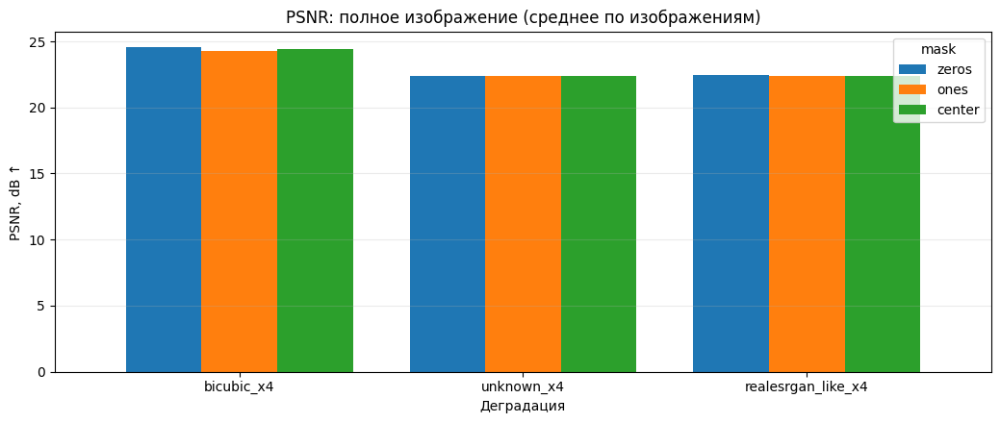

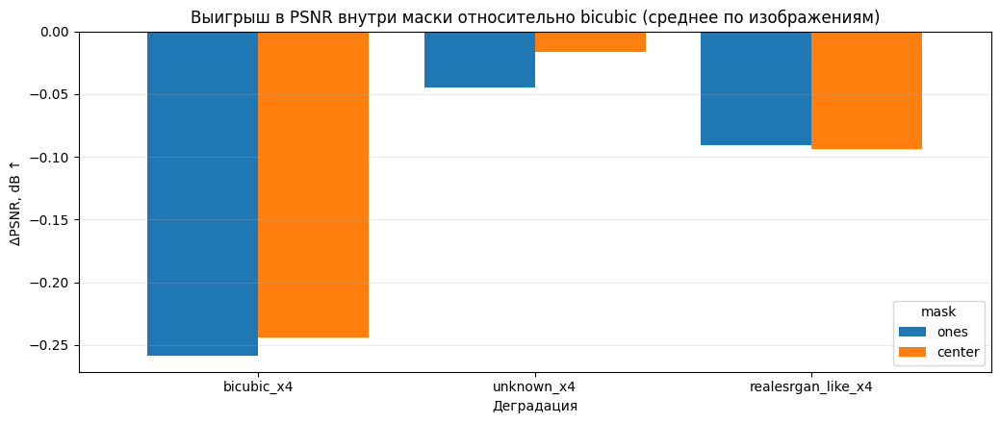

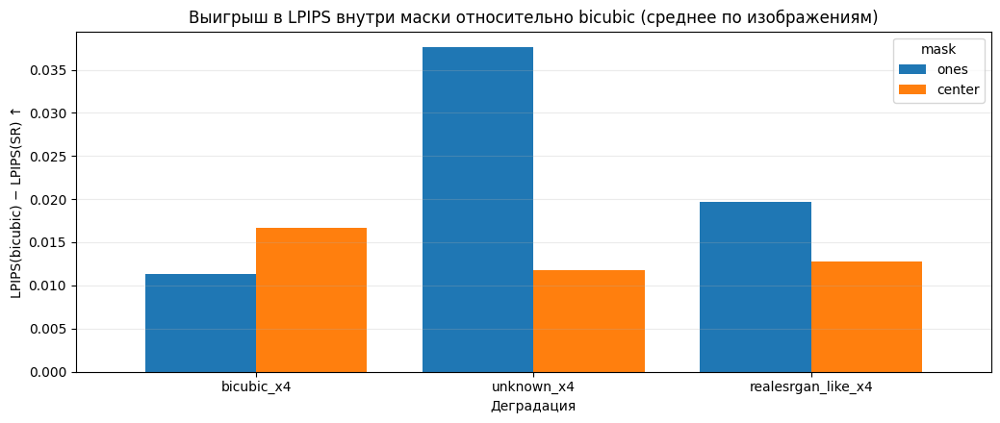

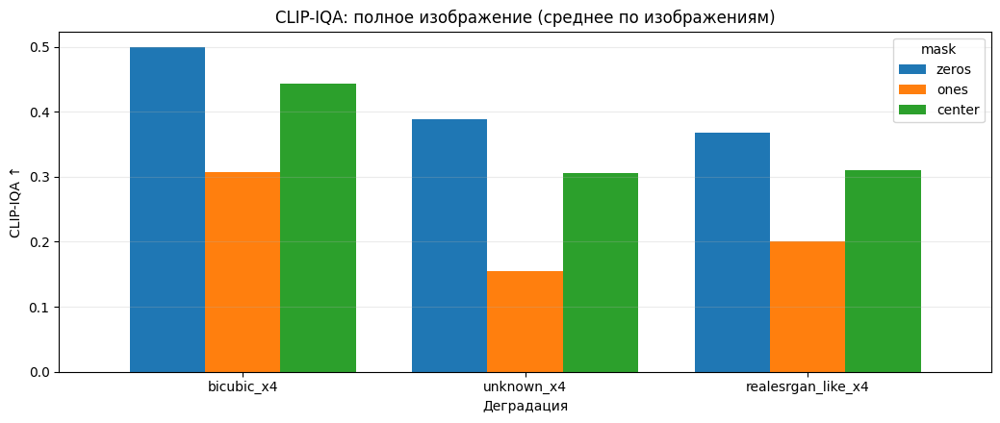

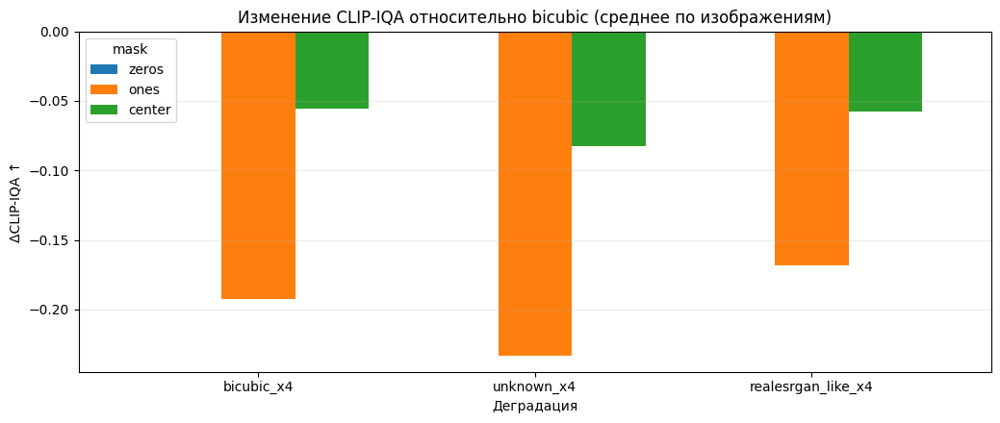

In [22]:
def plot_metric(name, ylabel, filename, title, without_zeros=False):
    data = metrics[metrics["mask"] != "zeros"] if without_zeros else metrics
    data = data.copy()
    data[name] = data[name].replace([np.inf, -np.inf], np.nan)
    pivot = data.pivot_table(index="degradation", columns="mask", values=name, aggfunc="mean")
    pivot = pivot.reindex(
        index=DEGRADATIONS,
        columns=tuple(m for m in MASKS if not (without_zeros and m == "zeros"))
    )
    ax = pivot.replace([np.inf, -np.inf], np.nan).plot.bar(
        figsize=(10.5, 4.5), rot=0, width=0.8)
    ax.set_title(f"{title} (среднее по изображениям)")
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Деградация")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.savefig(RESULTS / "plots" / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

plot_metric("PSNR_full_result", "PSNR, dB ↑", "PSNR_full.png", "PSNR: полное изображение")
plot_metric("delta_PSNR_masked_dB", "ΔPSNR, dB ↑", "PSNR_masked_gain.png",
            "Выигрыш в PSNR внутри маски относительно bicubic", without_zeros=True)
plot_metric("delta_LPIPS_masked", "LPIPS(bicubic) − LPIPS(SR) ↑", "LPIPS_masked_gain.png",
            "Выигрыш в LPIPS внутри маски относительно bicubic", without_zeros=True)
plot_metric("CLIP_IQA_full_result", "CLIP-IQA ↑", "CLIP_IQA_full.png",
            "CLIP-IQA: полное изображение")
plot_metric("delta_CLIP_IQA_full", "ΔCLIP-IQA ↑", "CLIP_IQA_gain.png",
            "Изменение CLIP-IQA относительно bicubic")


In [26]:
import shutil
import numpy as np

from pathlib import Path
from google.colab import files
from IPython.display import display


summary = metrics[[
    "image_id",
    "source_file",
    "degradation",
    "mask",
    "mask_fraction",
    "PSNR_full_result",
    "PSNR_masked_baseline",
    "PSNR_masked_result",
    "delta_PSNR_masked_dB",
    "LPIPS_masked_baseline",
    "LPIPS_masked_result",
    "delta_LPIPS_masked",
    "CLIP_IQA_full_baseline",
    "CLIP_IQA_full_result",
    "delta_CLIP_IQA_full",
    "MAE_outside_vs_bicubic"
]].copy()

summary.to_csv(
    RESULTS / "summary.csv",
    index=False,
    na_rep="NaN",
    float_format="%.6f"
)


aggregate = (
    metrics
    .drop(columns=["image_id", "source_file"])
    .replace([np.inf, -np.inf], np.nan)
    .groupby(["degradation", "mask"], sort=False)
    .mean(numeric_only=True)
    .reset_index()
)

aggregate.to_csv(
    RESULTS / "metrics_mean.csv",
    index=False,
    na_rep="NaN",
    float_format="%.8f"
)

display(aggregate.round(4))


archive = shutil.make_archive(
    base_name="/content/CV3_results",
    format="zip",
    root_dir=str(RESULTS)
)

archive_path = Path(archive)


if not archive_path.is_file():
    raise FileNotFoundError(f"Архив не найден: {archive_path}")

if archive_path.stat().st_size == 0:
    raise RuntimeError("Создан пустой архив")


print("\n========== RESULTS ==========")

print("Архив:", archive_path)
print("Размер:", round(archive_path.stat().st_size / 1024**2, 2), "MB")
print("Исходных изображений:", metrics["image_id"].nunique())
print("Экспериментов:", len(metrics))
print("Изображений:", len(list((RESULTS / "outputs").glob("*.png"))))
print("Сравнений:", len(list((RESULTS / "comparisons").glob("*.png"))))

print("=============================")


files.download(str(archive_path))

,degradation,mask,mask_fraction,PSNR_full_baseline,PSNR_full_result,PSNR_masked_baseline,PSNR_masked_result,delta_PSNR_masked_dB,PSNR_unmasked_result,LPIPS_full_baseline,LPIPS_full_result,LPIPS_masked_baseline,LPIPS_masked_result,delta_LPIPS_masked,CLIP_IQA_full_baseline,CLIP_IQA_full_result,delta_CLIP_IQA_full,MAE_outside_vs_bicubic
0,bicubic_x4,zeros,0.00,24.5379,24.5379,NaN,NaN,NaN,24.5379,0.4416,0.4416,NaN,NaN,NaN,0.4989,0.4989,0.0000,0.0
1,bicubic_x4,ones,1.00,24.5379,24.2795,24.5379,24.2795,-0.2584,NaN,0.4416,0.4303,0.4416,0.4303,0.0113,0.4989,0.3068,-0.1921,NaN
2,bicubic_x4,center,0.25,24.5379,24.4503,23.0735,22.8295,-0.2440,25.1722,0.4416,0.4351,0.5171,0.5004,0.0166,0.4989,0.4436,-0.0553,0.0
3,unknown_x4,zeros,0.00,22.4008,22.4008,NaN,NaN,NaN,22.4008,0.6692,0.6692,NaN,NaN,NaN,0.3883,0.3883,0.0000,0.0
4,unknown_x4,ones,1.00,22.4008,22.3561,22.4008,22.3561,-0.0447,NaN,0.6692,0.6316,0.6692,0.6316,0.0376,0.3883,0.1553,-0.2330,NaN
5,unknown_x4,center,0.25,22.4008,22.3949,21.0423,21.0258,-0.0165,22.9857,0.6692,0.6646,0.7117,0.6999,0.0118,0.3883,0.3058,-0.0825,0.0
6,realesrgan_like_x4,zeros,0.00,22.4438,22.4438,NaN,NaN,NaN,22.4438,0.6504,0.6504,NaN,NaN,NaN,0.3683,0.3683,0.0000,0.0
7,realesrgan_like_x4,ones,1.00,22.4438,22.3527,22.4438,22.3527,-0.0911,NaN,0.6504,0.6307,0.6504,0.6307,0.0197,0.3683,0.1999,-0.1684,NaN
8,realesrgan_like_x4,center,0.25,22.4438,22.4132,21.0797,20.9859,-0.0939,23.0345,0.6504,0.6459,0.7191,0.7063,0.0128,0.3683,0.3106,-0.0578,0.0



========== RESULTS ==========
Архив: /content/CV3_results.zip
Размер: 27.95 MB
Исходных изображений: 3
Экспериментов: 27
Изображений: 27
Сравнений: 27


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>